A notebook to test the functions of the new vrdr_resampler Python module.

In [2]:
# auto reload
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
import vrdr_resampler as vrdr
from pathlib import Path

# Loading the CaSSIS Spectral Response

In [4]:
# instrument path
inst_path = Path('instrument_response', 'CaSSIS-2019.csv')

In [5]:
cassis_data = vrdr.load_channel_profiles(inst_path)
band_arr, arr_wvls, band_list, band_cwls = vrdr.unpack_channel_profiles(cassis_data)

/Users/a-rogs/Documents/projects/uksapdra_2024-2025/vrdr_resampler/vrdr_resampler.py:149: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


(<Figure size 500x400 with 1 Axes>,
 <Axes: title={'center': 'CaSSIS-2019 Channel Profiles'}, xlabel='Wavelength (nm)', ylabel='Spectral Response'>)

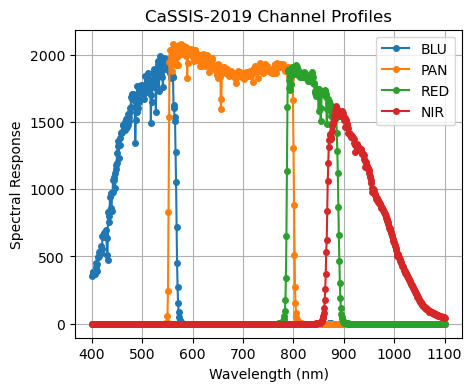

In [6]:
vrdr.plot_channel_profiles(cassis_data, instrument='CaSSIS-2019')

# Loading a VRDR Tile

Setting the data directory:

In [ ]:
vrdr_path = Path('/Volumes', 'RS_STORE', 'vrdr')

Setting the output directory:

In [10]:
output_path = vrdr_path.parent / 'vrdr_cassis'
output_path.mkdir(exist_ok=True) 

Finding the quadrant directories:

In [11]:
mc_paths = vrdr.get_quadrant_dirs(vrdr_path)
mc_path = mc_paths[0]  # Example: process the first quadrant directory

Finding the tile paths in the quadrant directory:

In [12]:
lbl_paths = vrdr.get_tile_lbls(mc_path)
lbl_path = lbl_paths[0]  # Example: process the first label file

Preparing the output file directory:

In [13]:
out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=True)
out_dir

Output directory exists, overwriting:  /Volumes/RS_STORE/vrdr_cassis/mc11/t1082_vrral_05n318_0654_1


PosixPath('/Volumes/RS_STORE/vrdr_cassis/mc11/t1082_vrral_05n318_0654_1')

Loading the tile, getting the band centre-wavelengths, and the no-data value:

In [15]:
vrdr_cube, vrdr_cwls, no_data = vrdr.load_vrdr_tile(lbl_path)

# Resampling to the Instrument Spectral Response

In [24]:
cifcub = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_cwls, no_data)

## Verifying the Resampling Method

In [22]:
b_w = arr_wvls
c_w = vrdr_cwls
b_a = band_arr
resampled_profiles = [vrdr.interp_band_profile(b_p, b_w, c_w) for b_p in b_a.T]

In [23]:
import numpy as np
import pandas as pd
resampled_inst = pd.DataFrame(data=np.array(resampled_profiles).T, columns=band_list, index=c_w)

/Users/a-rogs/Documents/projects/uksapdra_2024-2025/vrdr_resampler/vrdr_resampler.py:149: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


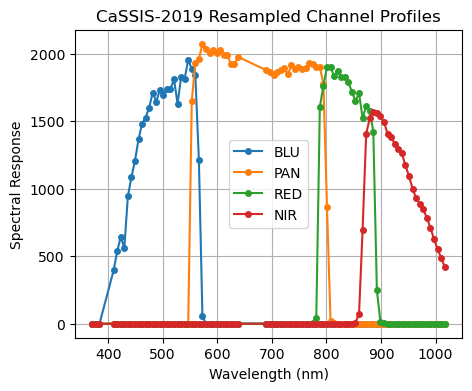

In [18]:
fig, ax = vrdr.plot_channel_profiles(resampled_inst, instrument='CaSSIS-2019 Resampled')

Checking a random selection of VRDR tile spectra

/var/folders/d4/cz7hyt3n1_b1r1pbq06pffy9mjlwy3/T/ipykernel_3633/335140315.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


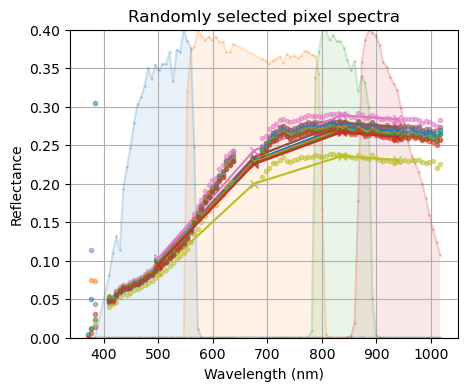

In [26]:
# select random locations in the last 2 dimensions of the cube
import random
import matplotlib.pyplot as plt

num_samples = 10
x_size, y_size = vrdr_cube.shape[1], vrdr_cube.shape[2]
random_coords = [(random.randint(0, x_size - 1), random.randint(0, y_size - 1)) for _ in range(num_samples)]

fig, ax = plt.subplots(figsize=(5, 4))

y_max = 0.4

for band in resampled_inst.columns:
    ax.plot(resampled_inst.index, y_max*resampled_inst[band]/np.nanmax(resampled_inst[band]), label=band, linestyle='-',marker='o', alpha=0.2, markersize=1)
    # fill the area under each band profile
    ax.fill_between(resampled_inst.index, 0, y_max*resampled_inst[band]/np.nanmax(resampled_inst[band]), alpha=0.1)

for x, y in random_coords:
    vrdr_spectrum = vrdr_cube[:, x, y]
    cassis_spectrum = cifcub[:, x, y]

    ax.plot(vrdr_wvls, vrdr_spectrum, label=f'{x,y}', marker='o', markersize=3, linestyle='None', alpha=0.5)
    # get colour used in the plot above
    color = ax.get_lines()[-1].get_color()
    ax.plot(band_cwls, cassis_spectrum, label=f'{x,y}', marker='x', markersize=6, color=color)
    ax.set_xlabel('Wavelength (nm)')
    ax.set_ylabel('Reflectance')
# plt.legend()
ax.set_title(f'Randomly selected pixel spectra')
ax.set_ylim(0, y_max)
ax.grid()
fig.show()

Note that data points with wavelengths <400 nm (i.e. the apparently noisy channels) are 0-weighted by the CaSSIS BLU transmission, so they effectively are not counted.

# Prepare Products

In [51]:
cstcub, st_params = vrdr.stretch_cube(cifcub, no_data) # cstcub = cassis stretched cube

/Users/a-rogs/Documents/projects/uksapdra_2024-2025/vrdr_resampler/vrdr_resampler.py:28: RuntimeWarning: invalid value encountered in cast
  


In [74]:
mask = (cifcub == no_data)
cifcub = np.where(mask, np.nan, cifcub)
stretch_params = np.nanpercentile(cifcub, [0.01, 99.95], axis=(1,2))
cstcub = cifcub - stretch_params[0][:, np.newaxis, np.newaxis] / (stretch_params[1][:, np.newaxis, np.newaxis] - stretch_params[0][:, np.newaxis, np.newaxis])
cstcub = np.clip(cstcub, 0, 1)
cstcub2 = np.round(cstcub * 254)
cstcub2[mask] = 255
# cstcub2 = cstcub2.astype(np.uint8)

In [72]:
np.rint(cstcub*254).astype(int)

/var/folders/d4/cz7hyt3n1_b1r1pbq06pffy9mjlwy3/T/ipykernel_3633/1245963021.py:1: RuntimeWarning: invalid value encountered in cast
  np.rint(cstcub*254).astype(int)


array([[[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]],

       [[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]]], shape=(4, 3271, 3259))

In [31]:
st_params

[(np.float64(0.06471115304002323), np.float64(0.12208039412950063)),
 (np.float64(0.13746727807248985), np.float64(0.29846019432283233)),
 (np.float64(0.148631580823931), np.float64(0.3610582101950401)),
 (np.float64(0.14188486502281877), np.float64(0.3559057229379946))]

/opt/homebrew/Caskroom/miniconda/base/envs/vrdr_resampler/lib/python3.13/site-packages/osgeo/gdal.py:311: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


Browse product exported: /Volumes/RS_STORE/vrdr_cassis/mc11/t1082_vrral_05n318_0654_1/t1082_cbpnpb_05n318_0654_1.tif


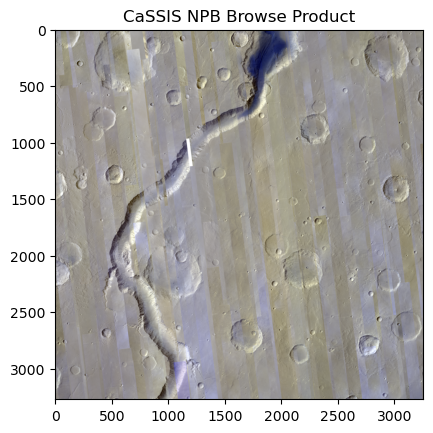

Browse product exported: /Volumes/RS_STORE/vrdr_cassis/mc11/t1082_vrral_05n318_0654_1/t1082_cbpnrb_05n318_0654_1.tif


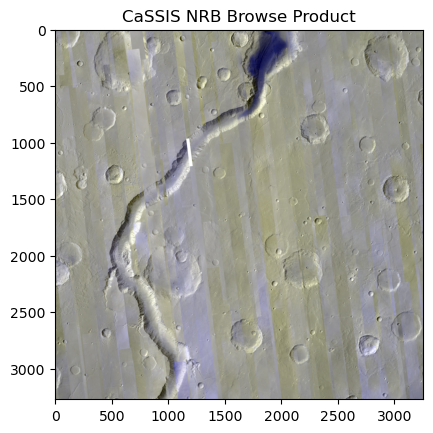

Browse product exported: /Volumes/RS_STORE/vrdr_cassis/mc11/t1082_vrral_05n318_0654_1/t1082_cbpnrp_05n318_0654_1.tif


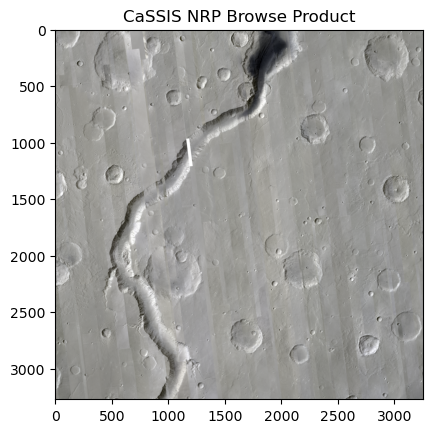

Browse product exported: /Volumes/RS_STORE/vrdr_cassis/mc11/t1082_vrral_05n318_0654_1/t1082_cbprpb_05n318_0654_1.tif


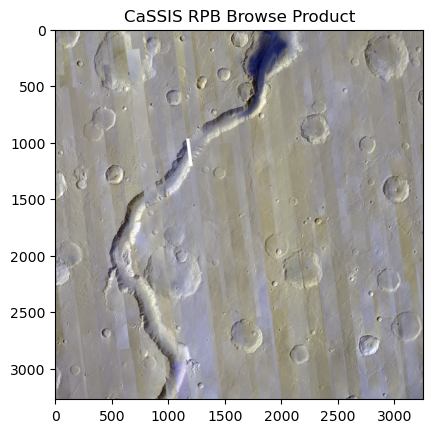

Stretching with lower=0.0836, upper=0.1579
Browse product exported: /Volumes/RS_STORE/vrdr_cassis/mc11/t1082_vrral_05n318_0654_1/t1082_cbprgb_05n318_0654_1.tif


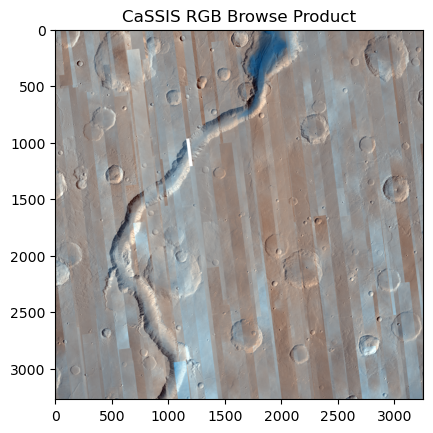

In [ ]:
for bp_id in ['NPB', 'NRB', 'NRP', 'RPB', 'RGB']:
    bp, bp_bands = vrdr.cassis_browse_product(bp_id, cifcub, cassis_stretch_cube, no_data)
    vrdr.export_bp_geotiff(bp, bp_id, 255, bp_bands, lbl_path, out_dir)
    plt.imshow(bp)
    plt.title(f'CaSSIS {bp_id} Browse Product')
    plt.show()

In [18]:
for bp_id in ['CBRC1', 'CBRC2']:
    sup, sup_bands = vrdr.cassis_composite_sup(bp_id, cassis_cube, no_data)
    bp_stretch = vrdr.stretch_cube(sup, no_data).transpose(1, 2, 0)
    vrdr.export_bp_geotiff(bp_stretch, bp_id, 255, sup_bands, lbl_path, out_dir)
    plt.imshow(bp_stretch)
    plt.title(f'CaSSIS {bp_id} Browse Product')
    plt.show()

AttributeError: module 'vrdr_resampler' has no attribute 'cassis_composite_sup'

# Export the Cube and Summary Product Stack to GeoTIFF with ENVI Headers

In [ ]:
out_file = vrdr.export_cube_geotiff(cassis_cube,band_list,band_cwls,no_data,lbl_path,out_dir)
out_hdr = vrdr.write_cube_envi_hdr(band_list, band_cwls, no_data,[4,2,1], lbl_path, out_dir)

In [ ]:
sups_cube, sp_list = vrdr.sups_from_cube(cassis_cube, ['PBR','PNR','RPR','ICE'],no_data)
out_file = vrdr.export_sups_geotiff(sups_cube,sp_list,no_data,lbl_path,out_dir)
out_hdr = vrdr.write_sups_envi_hdr(sp_list, no_data, [3, 1, 2], lbl_path, out_dir)

# Making Quadrant Wide Mosaics

In [ ]:
import rasterio as rio
r = rio.open(cube_file)

In [ ]:
stats = r.statistics(1)

/var/folders/d4/cz7hyt3n1_b1r1pbq06pffy9mjlwy3/T/ipykernel_19820/2732629979.py:1: RasterioDeprecationWarning: statistics() will be removed in 2.0.0. Please switch to stats().
  stats = r.statistics(1)


In [ ]:
stats.mean - 5*stats.std, stats.mean + 5*stats.std

(0.0663970786228385, 0.1116970159383075)

In [ ]:
cube = r.read(1)

In [ ]:
cube[cube == no_data] = np.nan
np.nanpercentile(cube, 0.01), np.nanpercentile(cube, 99.95)

(np.float64(0.06601752416589246), np.float64(0.1126212159384693))

In [ ]:
# get cassis quadrant directory paths
vrdr_path = Path('/Volumes', 'RS_STORE', 'vrdr_cassis')
output_path = vrdr_path.parent / 'vrdr_cassis_quads'
output_path.mkdir(exist_ok=True) 

mc_paths = vrdr.get_quadrant_dirs(vrdr_path)

for mc_path in mc_paths:
    print('Processing MC Directory: ', mc_path.name)
    # get lbl files but ignore hidden files
    tile_paths = vrdr.get_tile_dirs(mc_path)
    # sort

    tile_stretch_list = []
    for tile_path in tile_paths:
        print(' - ', tile_path.stem)
        # get tiff files
        cube_file = [f for f in tile_path.glob('*ccube*.tif')][0]        
        stretch_list = vrdr.read_geotiff_stretch_stats(cube_file)
        tile_stretch_list.append(np.array(stretch_list))
    tile_stretch_array = np.array(tile_stretch_list)

    stretch_min = np.min(tile_stretch_array[:,:,0], axis=0)
    stretch_max = np.max(tile_stretch_array[:,:,1], axis=0)

    for tile_path in tile_paths:
        print(' - ', tile_path.stem)

        cube_file = [f for f in tile_path.glob('*ccube*.tif')][0]
        cube, no_data = vrdr.read_geotiff_cube(cube_file)
        gbl_stretch_cube = vrdr.stretch_cube(cube, no_data, stretch_min=stretch_min, stretch_max=stretch_max)
        npb_gbl, npb_list = vrdr.cassis_browse_product('NPB', cube, gbl_stretch_cube, no_data)

        # get the label path from the vrdr directory
        lbl_path = Path(mc_path.parent.parent, 'vrdr', mc_path.stem, f'{tile_path.stem}.lbl')

        out_path = Path(output_path, mc_path.stem)
        out_path.mkdir(parents=True, exist_ok=True)

        vrdr.export_bp_geotiff(npb_gbl, 'NPBGBL', 255, npb_list, lbl_path, tile_path)
        

Processing MC Directory:  mc11
 -  t1082_vrral_05n318_0654_1
 -  t1083_vrral_05n323_0654_1
 -  t1084_vrral_05n328_0654_1
 -  t1085_vrral_05n333_0654_1
 -  t1086_vrral_05n338_0654_1
 -  t1087_vrral_05n343_0654_1
 -  t1088_vrral_05n348_0654_1
 -  t1089_vrral_05n353_0654_1
 -  t1090_vrral_05n358_0654_1
 -  t1154_vrral_10n318_0654_1
 -  t1155_vrral_10n323_0654_1
 -  t1156_vrral_10n328_0654_1
 -  t1157_vrral_10n333_0654_1
 -  t1158_vrral_10n338_0654_1
 -  t1159_vrral_10n343_0654_1
 -  t1160_vrral_10n348_0654_1
 -  t1161_vrral_10n353_0654_1
 -  t1162_vrral_10n358_0654_1
 -  t1226_vrral_15n318_0654_1
 -  t1227_vrral_15n323_0654_1
 -  t1228_vrral_15n328_0654_1
 -  t1229_vrral_15n333_0654_1
 -  t1230_vrral_15n338_0654_1
 -  t1231_vrral_15n343_0654_1
 -  t1232_vrral_15n348_0654_1
 -  t1233_vrral_15n353_0654_1
 -  t1234_vrral_15n358_0654_1
 -  t1298_vrral_20n318_0654_1
 -  t1299_vrral_20n323_0654_1
 -  t1300_vrral_20n328_0654_1
 -  t1301_vrral_20n333_0654_1
 -  t1302_vrral_20n338_0654_1
 -  t1303

IndexError: list index out of range

# Running the Loop

In [98]:
inst_path = Path('.', 'CaSSIS-2019.csv')
vrdr_path = Path('/Volumes', 'RS_STORE', 'vrdr')
output_path = vrdr_path.parent / 'vrdr_cassis'
output_path.mkdir(exist_ok=True) 

cassis_data = vrdr.load_channel_profiles(inst_path)
band_arr, arr_wvls, band_list, band_cwls = vrdr.unpack_channel_profiles(cassis_data)

mc_paths = vrdr.get_quadrant_dirs(vrdr_path)

for mc_path in mc_paths:
    if mc_path.stem not in ['mc16']:
        continue
    print('Processing MC Directory: ', mc_path.name)
    # get lbl files but ignore hidden files
    lbl_paths = vrdr.get_tile_lbls(mc_path)
    # sort
    
    for lbl_path in lbl_paths:
        print(' - ', lbl_path.stem)

        out_dir = vrdr.prepare_output_dir(lbl_path, mc_path, output_path, overwrite=False)
        if not out_dir:
            continue

        vrdr_cube, vrdr_wvls, no_data = vrdr.load_vrdr_tile(lbl_path)

        cassis_cube = vrdr.resample_cube(band_arr, arr_wvls, vrdr_cube, vrdr_wvls, no_data)

        cassis_stretch_cube = vrdr.stretch_cube(cassis_cube, no_data)

        for bp_id in ['NPB', 'NRB', 'NRP', 'RPB', 'RGB']:
            bp, bp_bands = vrdr.cassis_browse_product(bp_id, cassis_cube, cassis_stretch_cube, no_data)
            vrdr.export_bp_geotiff(bp, bp_id, 255, bp_bands, lbl_path, out_dir)

        for bp_id in ['CBRC1', 'CBRC2']:
            sup, sup_bands = vrdr.cassis_composite_sup(bp_id, cassis_cube, no_data)
            bp_stretch = vrdr.stretch_cube(sup, no_data).transpose(1, 2, 0)
            vrdr.export_bp_geotiff(bp_stretch, bp_id, 255, sup_bands, lbl_path, out_dir)

        out_file = vrdr.export_cube_geotiff(cassis_cube,band_list,band_cwls,no_data,lbl_path,out_dir)
        out_hdr = vrdr.write_cube_envi_hdr(band_list, band_cwls, no_data,[4,2,1], lbl_path, out_dir)

        sups_cube, sp_list = vrdr.sups_from_cube(cassis_cube, ['PBR','PNR','RPR','ICE'],no_data)
        out_file = vrdr.export_sups_geotiff(sups_cube,sp_list,no_data,lbl_path,out_dir)
        out_hdr = vrdr.write_sups_envi_hdr(sp_list, no_data, [3, 1, 2], lbl_path, out_dir)
        

Processing MC Directory:  mc16
 -  t0623_vrral_25s183_0654_1
Output directory exists, skipping:  /Volumes/RS_STORE/vrdr_cassis/mc16/t0623_vrral_25s183_0654_1
 -  t0624_vrral_25s188_0654_1
Output directory exists, skipping:  /Volumes/RS_STORE/vrdr_cassis/mc16/t0624_vrral_25s188_0654_1
 -  t0625_vrral_25s193_0654_1
Output directory exists, skipping:  /Volumes/RS_STORE/vrdr_cassis/mc16/t0625_vrral_25s193_0654_1
 -  t0626_vrral_25s198_0654_1
Output directory exists, skipping:  /Volumes/RS_STORE/vrdr_cassis/mc16/t0626_vrral_25s198_0654_1
 -  t0627_vrral_25s203_0654_1
Output directory exists, skipping:  /Volumes/RS_STORE/vrdr_cassis/mc16/t0627_vrral_25s203_0654_1
 -  t0628_vrral_25s208_0654_1
Output directory exists, skipping:  /Volumes/RS_STORE/vrdr_cassis/mc16/t0628_vrral_25s208_0654_1
 -  t0629_vrral_25s213_0654_1
Output directory exists, skipping:  /Volumes/RS_STORE/vrdr_cassis/mc16/t0629_vrral_25s213_0654_1
 -  t0630_vrral_25s218_0654_1
Output directory exists, skipping:  /Volumes/RS_ST

TypeError: 'NoneType' object is not subscriptable

Now I'd like a quick script that loops over all processed tiles in a quadrant, gets the quadrant-wide stretch parameters, and then makes a mosaic browse product at that level.